# Bike Rental Prediction

Predict daily bike rentals using weather and calendar features. Chronological evaluation with preprocessing pipelines and time-series cross-validation.

Download and extract `day.csv` from the [UCI Bike Sharing dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), then place it in `data/day.csv`. In Colab, upload `day.csv` to the runtime instead. Run the cells in order.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestRegressor


In [ ]:
from pathlib import Path

DATA_PATH = Path("data/day.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("day.csv")  # Colab runtime upload
if not DATA_PATH.exists():
    raise FileNotFoundError("Place day.csv in data/ or upload it to the Colab runtime.")

df = pd.read_csv(DATA_PATH)
df.head()


## Explore the dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [ ]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [ ]:
df['dteday']=pd.to_datetime(df['dteday'])


In [ ]:
df = df.sort_values('dteday')
df['dteday'].head()

,dteday
0,2011-01-01
1,2011-01-02
2,2011-01-03
3,2011-01-04
4,2011-01-05


## Chronological train/test split
The first 80% of days are used for training; the last 20% are held out.

In [ ]:
split_index=int(len(df)*0.8)
split_index

584

In [ ]:
train_set=df.iloc[:split_index].copy()
test_set=df.iloc[split_index:].copy()
print("Train:", train_set.shape)
print("Test:", test_set.shape)

Train: (584, 16)
Test: (147, 16)


In [ ]:
bike =train_set.copy()
bike

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
579,580,2012-08-02,3,1,8,0,4,1,1,0.752500,0.707088,0.659583,0.129354,983,6278,7261
580,581,2012-08-03,3,1,8,0,5,1,2,0.765833,0.722867,0.642500,0.215792,1328,5847,7175
581,582,2012-08-04,3,1,8,0,6,0,1,0.793333,0.751267,0.613333,0.257458,2345,4479,6824
582,583,2012-08-05,3,1,8,0,0,0,1,0.769167,0.731079,0.652500,0.290421,1707,3757,5464


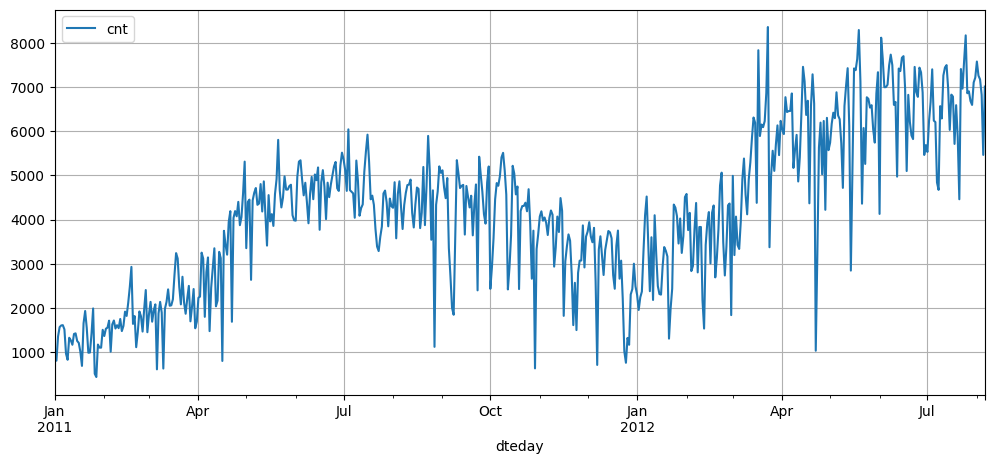

In [ ]:
bike.plot(
    x='dteday',
    y='cnt',
    figsize=(12,5),
    grid=True
)
plt.show()

In [ ]:
corr_matrix = bike.corr(numeric_only=True)
corr_matrix['cnt'].sort_values(ascending=False)

,cnt
cnt,1.000000
registered,0.939581
casual,0.710940
atemp,0.689607
instant,0.685273
temp,0.684906
yr,0.540158
season,0.288832
mnth,0.204591
workingday,0.043224


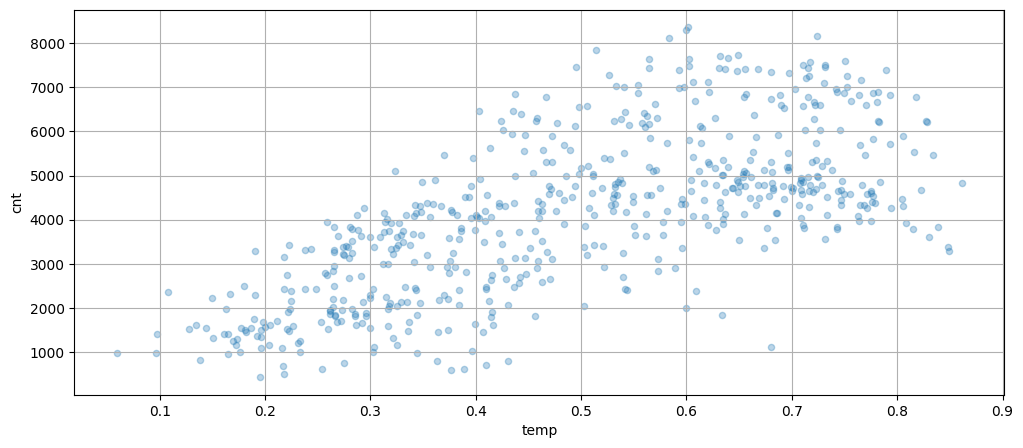

In [ ]:
bike.plot(
    kind='scatter',
    x='temp',
    y='cnt',
    alpha=0.3,
    figsize=(12,5),
    grid=True
)
plt.show()

In [ ]:
train_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 584 entries, 0 to 583
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     584 non-null    int64         
 1   dteday      584 non-null    datetime64[ns]
 2   season      584 non-null    int64         
 3   yr          584 non-null    int64         
 4   mnth        584 non-null    int64         
 5   holiday     584 non-null    int64         
 6   weekday     584 non-null    int64         
 7   workingday  584 non-null    int64         
 8   weathersit  584 non-null    int64         
 9   temp        584 non-null    float64       
 10  atemp       584 non-null    float64       
 11  hum         584 non-null    float64       
 12  windspeed   584 non-null    float64       
 13  casual      584 non-null    int64         
 14  registered  584 non-null    int64         
 15  cnt         584 non-null    int64         
dtypes: datetime64[ns](1), floa

## Features and target
Exclude `casual` and `registered`: their sum is the target `cnt`, so they would leak the answer. Exclude the row identifier and raw date.

In [ ]:
X_train=train_set.drop(
    columns=['dteday','casual','registered','cnt','instant']
)
y_train=train_set['cnt']
print(X_train.shape)
print(y_train.shape)

(584, 11)
(584,)


## Preprocessing
Numeric: median imputation and standardization. Categorical: most-frequent imputation and one-hot encoding. All CV preprocessing is learned inside each fold.

In [ ]:
num_features=['temp','atemp','hum','windspeed']
cat_features=['season','yr','mnth','holiday','weekday','workingday','weathersit']

In [ ]:
num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)
cat_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

In [ ]:
preprocessing= ColumnTransformer(
    [
     ('numeric', num_pipeline, num_features),
     ('categorical', cat_pipeline, cat_features)
    ]
)


In [ ]:
X_train_prepared=preprocessing.fit_transform(X_train)


In [ ]:
print('X_train shape', X_train.shape)
print('X_train_prepared shape', X_train_prepared.shape)


X_train shape (584, 11)
X_train_prepared shape (584, 36)


In [ ]:
preprocessing.get_feature_names_out()

array(['numeric__temp', 'numeric__atemp', 'numeric__hum',
       'numeric__windspeed', 'categorical__season_1',
       'categorical__season_2', 'categorical__season_3',
       'categorical__season_4', 'categorical__yr_0', 'categorical__yr_1',
       'categorical__mnth_1', 'categorical__mnth_2',
       'categorical__mnth_3', 'categorical__mnth_4',
       'categorical__mnth_5', 'categorical__mnth_6',
       'categorical__mnth_7', 'categorical__mnth_8',
       'categorical__mnth_9', 'categorical__mnth_10',
       'categorical__mnth_11', 'categorical__mnth_12',
       'categorical__holiday_0', 'categorical__holiday_1',
       'categorical__weekday_0', 'categorical__weekday_1',
       'categorical__weekday_2', 'categorical__weekday_3',
       'categorical__weekday_4', 'categorical__weekday_5',
       'categorical__weekday_6', 'categorical__workingday_0',
       'categorical__workingday_1', 'categorical__weathersit_1',
       'categorical__weathersit_2', 'categorical__weathersit_3'],
      d

## Train baseline models

In [ ]:
lin_reg = make_pipeline(
    clone(preprocessing),
    LinearRegression()
)
lin_reg.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['temp', 'atemp', 'hum',
                                                   'windspeed']),
                                                 ('categorical',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['season', 'yr', 'mnth',
                                                   'holiday', 'weekday',
                                                   'workingday',
                                                   'weathersit'])])),
                ('linearregression', LinearRegression())])

In [ ]:
train_predictions = lin_reg.predict(X_train)

lin_train_rmse = root_mean_squared_error(
    y_train,
    train_predictions
)

print("Linear Regression training RMSE:", lin_train_rmse)

Linear Regression training RMSE: 678.9431879339729


In [ ]:
tree_reg = make_pipeline(
    clone(preprocessing),
    DecisionTreeRegressor(random_state=42)
)

tree_reg.fit(X_train, y_train)

tree_train_predictions = tree_reg.predict(X_train)

tree_train_rmse = root_mean_squared_error(
    y_train,
    tree_train_predictions
)

print("Decision Tree training RMSE:", tree_train_rmse)

Decision Tree training RMSE: 0.0


## Time-series cross-validation
Five expanding-window folds preserve chronological order.

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

lin_cv_rmses = -cross_val_score(
    lin_reg,
    X_train,
    y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error"
)

print("Validation RMSEs:", lin_cv_rmses)
print("Mean validation RMSE:", lin_cv_rmses.mean())

Validation RMSEs: [1016.8082322   950.17157672 1049.96500438 1142.17872653 1005.05955887]
Mean validation RMSE: 1032.836619741644


In [ ]:
tree_cv_rmses = -cross_val_score(
    tree_reg,
    X_train,
    y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error"
)

print("Decision Tree validation RMSEs:", tree_cv_rmses)
print("Mean validation RMSE:", tree_cv_rmses.mean())

Decision Tree validation RMSEs: [1706.05062107 1164.57459159 1235.75724103 2112.74200346 1148.09875559]
Mean validation RMSE: 1473.4446425482279


## Random Forest

In [ ]:
forest_reg = make_pipeline(
    clone(preprocessing),
    RandomForestRegressor(random_state=42)
)

forest_reg.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['temp', 'atemp', 'hum',
                                                   'windspeed']),
                                                 ('categorical',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['season', 'yr', 'mnth',
                                                   'holiday', 'weekday',
                                                   'workingday',
                                                   'weathersit'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

In [ ]:
forest_train_predictions = forest_reg.predict(X_train)

forest_train_rmse = root_mean_squared_error(
    y_train,
    forest_train_predictions
)

print("Random Forest training RMSE:", forest_train_rmse)

Random Forest training RMSE: 229.05725641440807


In [ ]:
forest_cv_rmses = -cross_val_score(
    forest_reg,
    X_train,
    y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error"
)

print("Validation RMSEs:", forest_cv_rmses)
print("Mean validation RMSE:", forest_cv_rmses.mean())

Validation RMSEs: [1659.53289522  850.00973008 1226.88908905 1801.95454377  948.04328127]
Mean validation RMSE: 1297.2859078765705


## Hyperparameter tuning
Nine Random Forest configurations, evaluated with the same time-series folds.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

forest_pipeline = Pipeline([
    ("preprocessing", clone(preprocessing)),
    ("random_forest", RandomForestRegressor(random_state=42))
])

param_grid = {
    "random_forest__max_depth": [5, 10, None],
    "random_forest__min_samples_leaf": [1, 3, 10]
}

grid_search = GridSearchCV(
    forest_pipeline,
    param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None),
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('numeric',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('standardscaler',
                                                                                          StandardScaler())]),
                                                                         ['temp',
                                                                          'atemp',
                                                                          'hum',
                                                                          'windspeed']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('simpl...
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['season',
                                                                          'yr',
                                                                          'mnth',
                                                                          'holiday',
                                                                          'weekday',
                                                                          'workingday',
                                                                          'weathersit'])])),
                                       ('random_forest',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'random_forest__max_depth': [5, 10, None],
                         'random_forest__min_samples_leaf': [1, 3, 10]},
             scoring='neg_root_mean_squared_error')

In [ ]:
print("Best parameters:", grid_search.best_params_)
print("Best mean validation RMSE:", -grid_search.best_score_)

Best parameters: {'random_forest__max_depth': 5, 'random_forest__min_samples_leaf': 1}
Best mean validation RMSE: 1288.2516906928927


In [ ]:
best_forest = grid_search.best_estimator_

## Final test evaluation
Linear Regression was selected using validation results before evaluating the held-out test period.

In [ ]:
X_test = test_set.drop(
    columns=["cnt", "casual", "registered", "instant", "dteday"]
)
y_test = test_set["cnt"].copy()

final_model = lin_reg

test_predictions = final_model.predict(X_test)

test_rmse = root_mean_squared_error(y_test, test_predictions)
print("Test RMSE:", test_rmse)

Test RMSE: 1102.6619968627017


## Save and reload the fitted pipeline

In [ ]:
import joblib

Path("models").mkdir(exist_ok=True)
model_path = Path("models/bike_model.pkl")
joblib.dump(final_model, model_path)


In [ ]:
loaded_model = joblib.load(model_path)

comparison = pd.DataFrame({
    "Actual": y_test.iloc[:5].to_numpy(),
    "Prediction": loaded_model.predict(X_test.iloc[:5])
})

comparison.round(0)

,Actual,Prediction
0,7273,6492.0
1,7534,6556.0
2,7286,6935.0
3,5786,6102.0
4,6299,6053.0


## Inspect test predictions

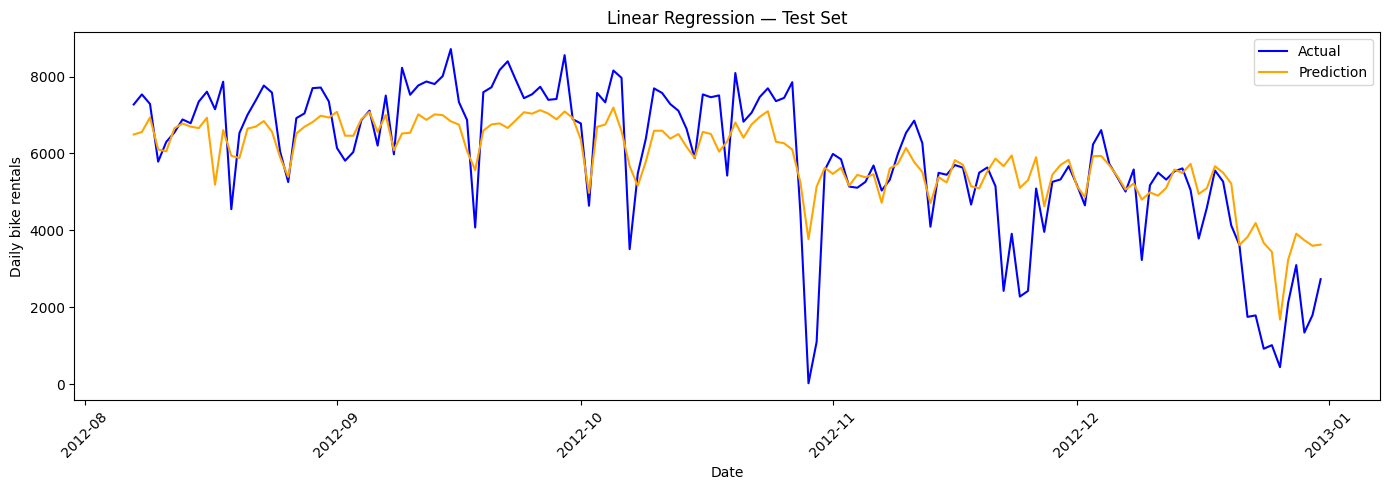

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    test_set["dteday"], y_test,
    label="Actual", color="blue"
)

plt.plot(
    test_set["dteday"], test_predictions,
    label="Prediction", color="orange"
)

plt.xlabel("Date")
plt.ylabel("Daily bike rentals")
plt.title("Linear Regression — Test Set")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Results and limitations

| Model | Training RMSE | Mean validation RMSE |
|---|---:|---:|
| Linear Regression | 678.94 | 1032.84 |
| Decision Tree | 0.00 | 1473.44 |
| Random Forest | 229.06 | 1297.29 |
| Tuned Random Forest | — | 1288.25 |

Selected model: **Linear Regression**. Held-out test RMSE: **1102.66 rentals/day**. These are saved outputs from the original Colab run; the portable version has not been rerun here.

Predictions track the broad demand pattern but miss some peaks and sudden drops. This is an educational baseline, not a deployed service. Only two years of historical data are represented; `yr` does not encode an ongoing future trend. Actual daily weather inputs also differ from the forecasts available when predicting future demand.
